In [1]:
import pandas as pd

df1 = pd.read_csv("../data/raw/AirQuality/combined_gee_pm25.csv")
df2 = pd.read_csv("../data/raw/AirQuality/gee_features_daily.csv")
df3 = pd.read_csv("../data/raw/AirQuality/pm25.csv")

print(df1.shape)
# because df1 is the combined, i don't need to deal with the other two datasets, but i will check them for missing values and duplicates

#print(df1.info())

print(df1.isna().sum())

print(df1.duplicated().sum())

#print(df1.describe())

# 6. Bad PM2.5 values
print("PM2.5 values that are missing:")
print(df1["pm25"].isna().sum())
print("less than or equal to 0:")
print((df1["pm25"] <= 0).sum())
print("greater than or equal to 500:")
print((df1["pm25"] >= 500).sum())

rows_before = len(df1)

df_clean = df1[df1["pm25"].notna() & (df1["pm25"] > 0) & (df1["pm25"] < 500)]

print("rows removed:", rows_before - len(df_clean))
print(df_clean.shape)

(41718, 15)
date                      0
datetime_utc              0
id                        0
latitude                  0
longitude                 0
temperature_celsius       0
pressure_mb               0
wind_u                    0
wind_v                    0
NO2                    2410
CO                     2410
O3                     2451
AOD                       0
pm25                      0
sensor_name               0
dtype: int64
0
PM2.5 values that are missing:
0
less than or equal to 0:
727
greater than or equal to 500:
8
rows removed: 735
(40983, 15)


In [2]:
import pandas as pd

cleaning_counts = pd.DataFrame({
    "item": [
        "rows_before_cleaning",
        "PM2.5_missing",
        "PM2.5_<=_0",
        "PM2.5_>=_500",
        "rows_removed_total",
        "rows_after_cleaning",
    ],
    "value": [41718, 0, 727, 8, 735, 40983],
})

cleaning_counts.to_csv("Exploratory_Data.csv", index=False)

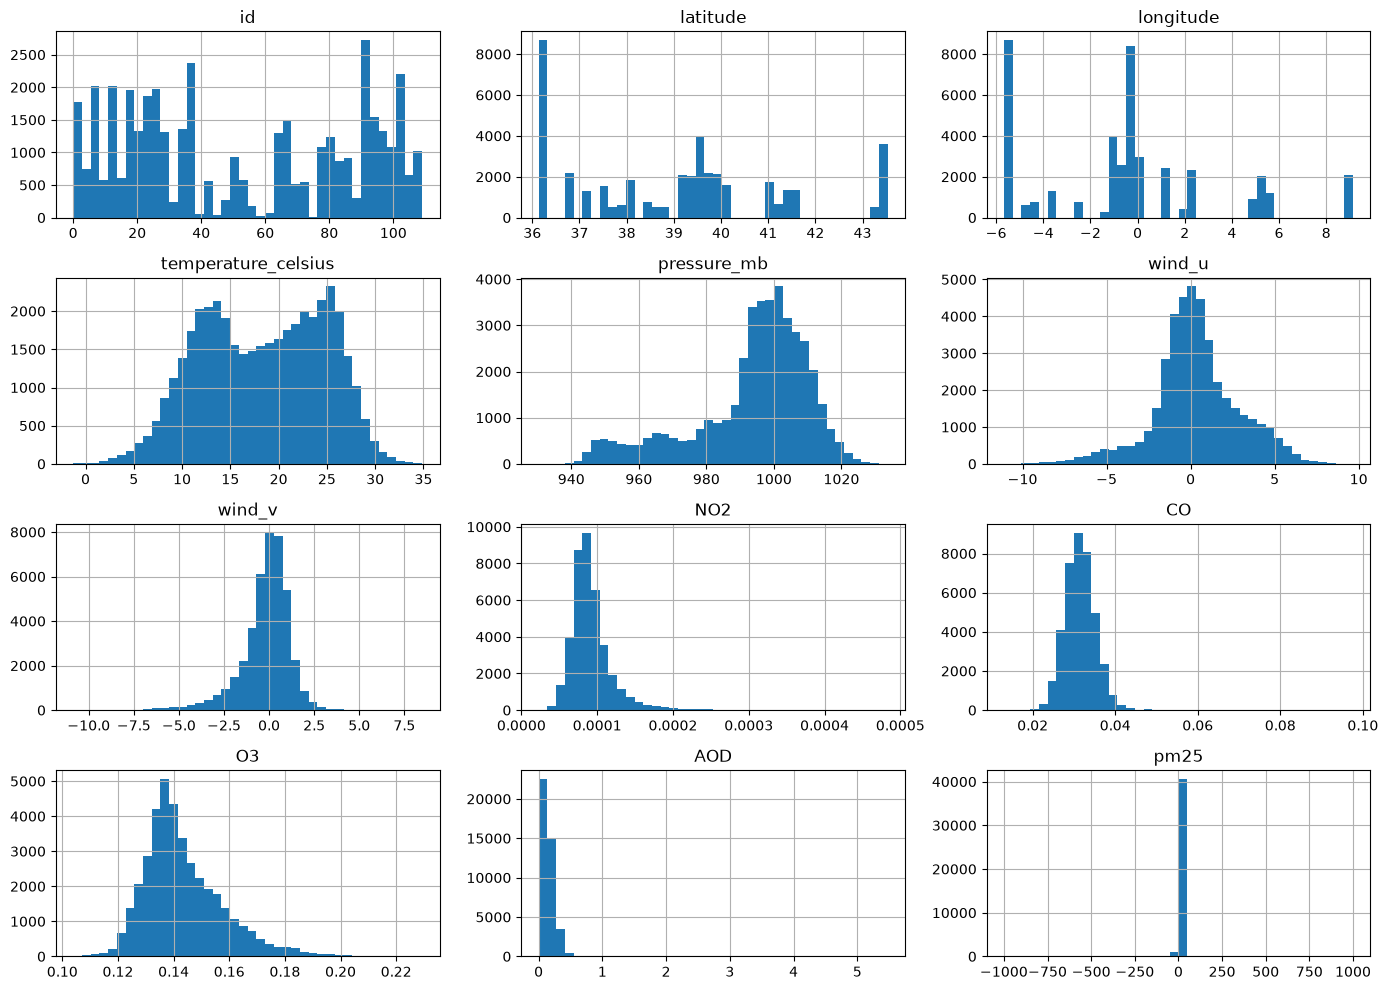

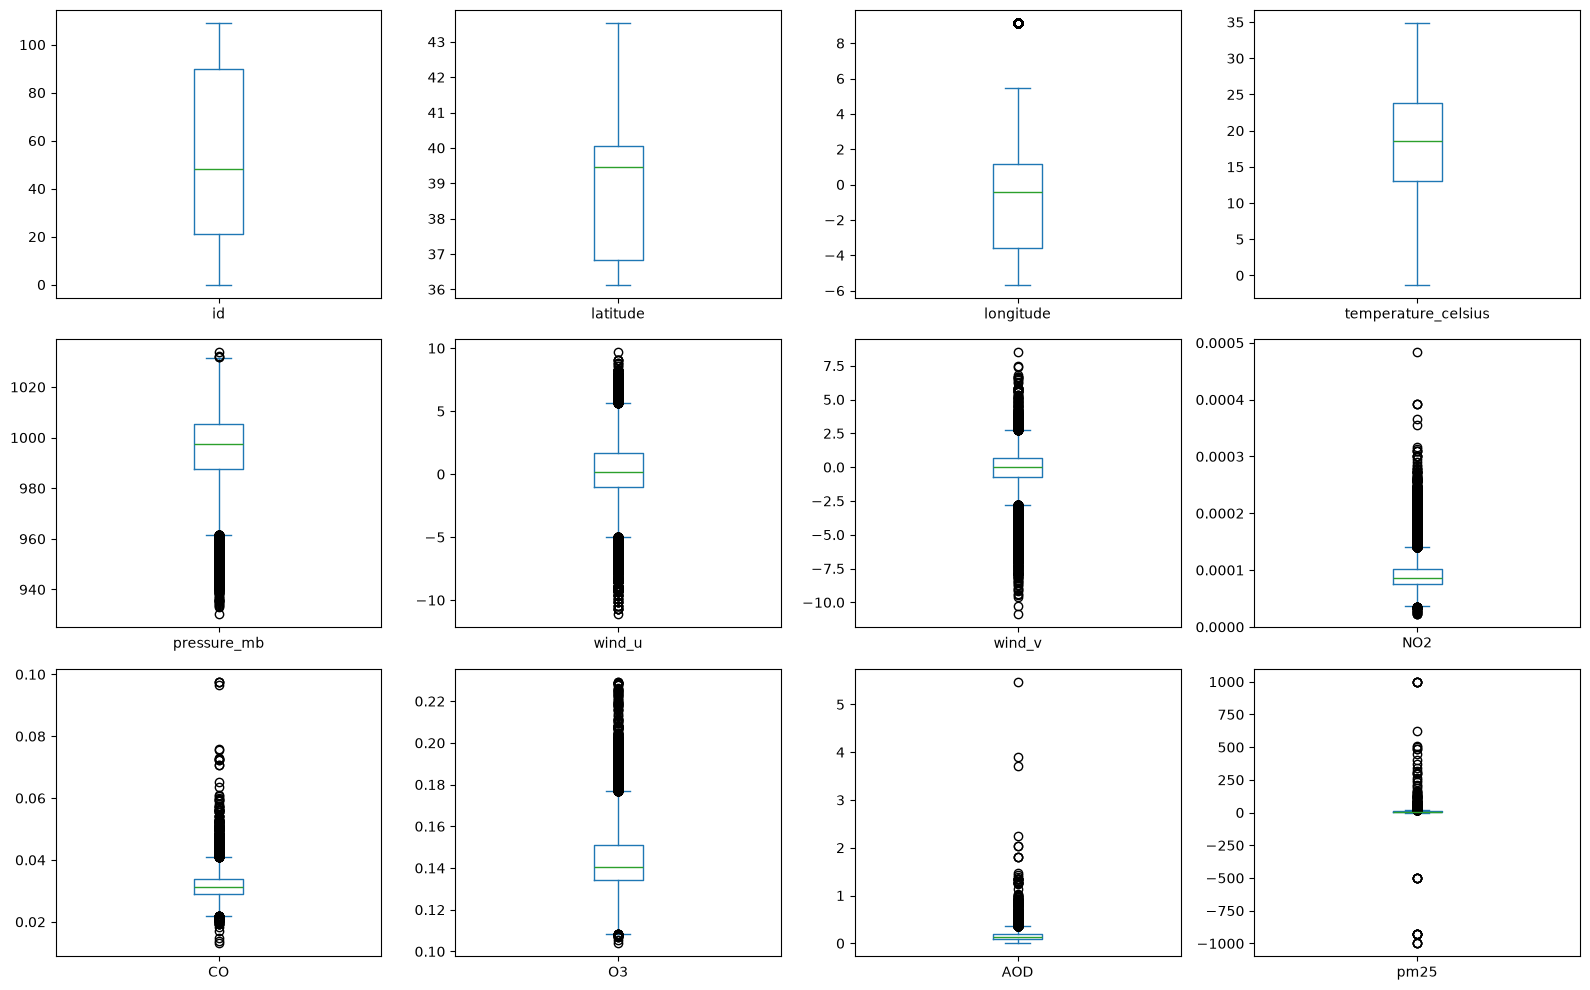

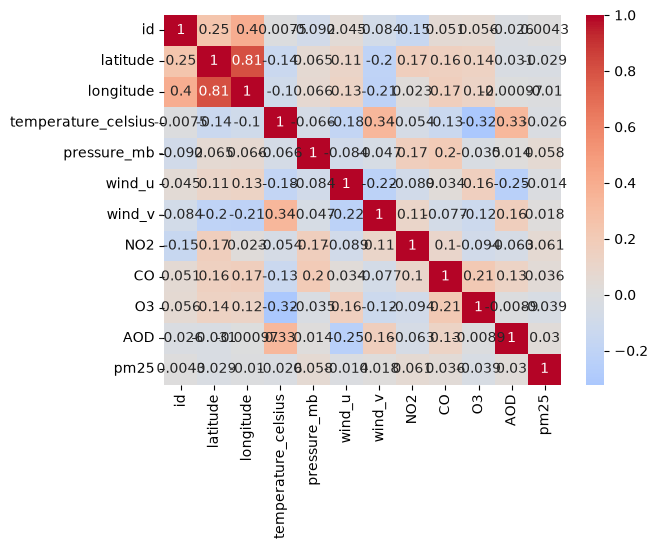

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ["datetime_utc", "id", "latitude", "longitude", "temperature_celsius", "pressure_mb", "wind_u", "wind_v", "NO2", "CO", "O3", "AOD", "pm25", "sensor_name"]  # use your real column names

# histograms
df1[cols].hist(bins=40, figsize=(14, 10))
plt.tight_layout()
plt.show()

# boxplots
df1[cols].plot(kind="box", subplots=True, layout=(3, 4), figsize=(16, 10))
plt.tight_layout()
plt.show()

# correlation heatmap
corr = df1.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.show()


In [17]:
import pandas as pd
from statsmodels.tsa.stattools import acf, adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox

DATE_COL, STATION_COL, TARGET = "date", "id", "pm25"

# Setup
df1 = df1[(df1[TARGET] > 0) & (df1[TARGET] < 500)].copy()
df1[DATE_COL] = pd.to_datetime(df1[DATE_COL], errors="coerce")
rows = []
def add(k, v): rows.append({"item": k, "value": v})

# Station check
print(df1["id"].nunique(), df1["sensor_name"].nunique(),
      df1[["latitude", "longitude"]].drop_duplicates().shape[0])

# Timestamp quality
add("invalid_dates", df1[DATE_COL].isna().sum())
df1 = df1.dropna(subset=[DATE_COL])
add("date_min", df1[DATE_COL].min().date())
add("date_max", df1[DATE_COL].max().date())
add("n_stations", df1[STATION_COL].nunique())
add("duplicate_station_date", df1.duplicated([STATION_COL, DATE_COL]).sum())

# Regularity per station
cov = []
for s, g in df1.groupby(STATION_COL):
    d = g[DATE_COL].drop_duplicates().sort_values()
    expected = (d.max() - d.min()).days + 1
    gaps = d.diff().dt.days.dropna()
    cov.append({"n_obs": len(d), "expected": expected,
                "coverage": len(d) / expected,
                "longest_gap": gaps.max() if len(gaps) else 0})
cov = pd.DataFrame(cov)
add("median_obs_per_station", cov.n_obs.median())
add("median_coverage_pct", round(cov.coverage.median() * 100, 1))
add("stations_with_coverage_below_80pct", (cov.coverage < 0.8).sum())
add("max_gap_days_any_station", cov.longest_gap.max())

# Drift by year and month
df1["year"], df1["month"] = df1[DATE_COL].dt.year, df1[DATE_COL].dt.month
for prefix in ["year", "month"]:
    for key, g in df1.groupby(prefix):
        x = g[TARGET]
        add(f"{prefix}_{key}_median", round(x.median(), 2))
        add(f"{prefix}_{key}_IQR", round(x.quantile(.75) - x.quantile(.25), 2))
        add(f"{prefix}_{key}_pct_above_25", round((x > 25).mean() * 100, 1))
        add(f"{prefix}_{key}_pct_above_50", round((x > 50).mean() * 100, 1))

# ACF, ADF, Ljung-Box on best-covered station
best = df1.groupby(STATION_COL).size().idxmax()
ser = (df1[df1[STATION_COL] == best].drop_duplicates(DATE_COL)
       .set_index(DATE_COL)[TARGET].sort_index().asfreq("D"))
add("diagnostic_station", best)
a = acf(ser, nlags=7, missing="conservative")
add("acf_lag1", round(a[1], 3))
add("acf_lag3", round(a[3], 3))
add("acf_lag7", round(a[7], 3))
clean = ser.dropna()
add("adf_pvalue", round(adfuller(clean)[1], 4))
add("ljungbox_pvalue_lag10", round(acorr_ljungbox(clean, lags=[10])["lb_pvalue"].iloc[0], 4))

# Save
out = pd.DataFrame(rows)
out.to_csv("Exploratory_temporal.csv", index=False, encoding="utf-8")
print(out.head(20))

95 91 95
                                  item       value
0                        invalid_dates           0
1                             date_min  2016-11-25
2                             date_max  2026-04-06
3                           n_stations          95
4               duplicate_station_date           0
5               median_obs_per_station       442.0
6                  median_coverage_pct        51.2
7   stations_with_coverage_below_80pct          93
8             max_gap_days_any_station      2383.0
9                     year_2016_median       10.17
10                       year_2016_IQR        7.06
11              year_2016_pct_above_25         1.8
12              year_2016_pct_above_50         0.0
13                    year_2017_median        7.67
14                       year_2017_IQR         7.3
15              year_2017_pct_above_25         3.8
16              year_2017_pct_above_50         0.3
17                    year_2018_median        7.02
18                    

C:\Users\douaa\AppData\Local\Temp\ipykernel_9068\2042439757.py:60: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  add("adf_pvalue", round(adfuller(clean)[1], 4))


In [19]:
# Per-station summary
df1 = df1.sort_values([STATION_COL, DATE_COL])
g = df1.groupby(STATION_COL)[DATE_COL]
st = pd.DataFrame({"n_obs": g.size(), "first": g.min(), "last": g.max()})
st["span_days"] = (st["last"] - st["first"]).dt.days + 1
st["coverage"] = st["n_obs"] / st["span_days"]
gap = g.diff().dt.days
st["n_lag1_valid"] = (gap == 1).groupby(df1[STATION_COL]).sum()
print(st[["n_obs", "coverage", "n_lag1_valid"]].describe())

# Threshold options
for n in [30, 50, 100, 200, 300]:
    keep = st[st["n_obs"] >= n].index
    print(f"min_obs={n}: stations kept={len(keep)}, rows kept={df1[STATION_COL].isin(keep).mean()*100:.1f}%")

# Apply the rule (change these two numbers after looking at the output above)
MIN_OBS = 100
MIN_LAG1 = 50
keep = st[(st["n_obs"] >= MIN_OBS) & (st["n_lag1_valid"] >= MIN_LAG1)].index
df_kept = df1[df1[STATION_COL].isin(keep)].copy()

# Log and save
extra = pd.DataFrame([
    {"item": "station_rule_min_obs", "value": MIN_OBS},
    {"item": "station_rule_min_lag1_pairs", "value": MIN_LAG1},
    {"item": "stations_before_filter", "value": st.shape[0]},
    {"item": "stations_kept", "value": len(keep)},
    {"item": "stations_dropped", "value": st.shape[0] - len(keep)},
    {"item": "rows_before_filter", "value": len(df1)},
    {"item": "rows_after_filter", "value": len(df_kept)},
])
out = pd.concat([out, extra], ignore_index=True)
out.to_csv("Exploratory_temporal.csv", index=False, encoding="utf-8")
pd.Series(keep, name=STATION_COL).to_csv("kept_stations.csv", index=False)
print(extra)

             n_obs   coverage  n_lag1_valid
count    95.000000  95.000000     95.000000
mean    431.400000   0.501310    286.936842
std     266.997227   0.158384    174.944417
min       4.000000   0.045259      0.000000
25%     205.500000   0.385521    155.000000
50%     442.000000   0.512195    291.000000
75%     646.500000   0.606576    444.500000
max    1042.000000   1.000000    686.000000
min_obs=30: stations kept=91, rows kept=99.9%
min_obs=50: stations kept=84, rows kept=99.2%
min_obs=100: stations kept=80, rows kept=98.6%
min_obs=200: stations kept=72, rows kept=95.4%
min_obs=300: stations kept=60, rows kept=88.1%
                          item  value
0         station_rule_min_obs    100
1  station_rule_min_lag1_pairs     50
2       stations_before_filter     95
3                stations_kept     80
4             stations_dropped     15
5           rows_before_filter  40983
6            rows_after_filter  40393


In [ ]:
from pathlib import Path
import shutil

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
print("repo root:", ROOT)

# Write preprocessing module
code = '''import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

TARGET = "pm25"
DROP_COLS = ["date", "datetime_utc", "id", "latitude", "longitude", "sensor_name",
             "year", "month", TARGET]

def get_features(df):
    return [c for c in df.columns if c not in DROP_COLS]

def make_pipeline(model, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)
'''
(ROOT / "src" / "preprocessing.py").write_text(code, encoding="utf-8")

# Move output files to the right folders
moves = {
    "Exploratory_Data.csv": "results",
    "Exploratory_temporal.csv": "results",
    "kept_stations.csv": "data/processed",
    "features_dev.csv": "data/processed",
    "features_test.csv": "data/processed",
    "folds_temporal.json": "folds",
    "folds_spatial.json": "folds",
    "folds_standard.json": "folds",
}
for name, dest in moves.items():
    f = Path.cwd() / name
    if f.exists():
        (ROOT / dest).mkdir(parents=True, exist_ok=True)
        shutil.move(str(f), str(ROOT / dest / name))
        print("moved", name, "->", dest)
    else:
        print("not found:", name)

repo root: c:\Users\douaa\pm25-forecasting
moved Exploratory_Data.csv -> results
moved Exploratory_temporal.csv -> results
moved kept_stations.csv -> data/processed
not found: features_dev.csv
not found: features_test.csv
not found: folds_temporal.json
not found: folds_spatial.json
not found: folds_standard.json


In [30]:
import sys, json
sys.path.append(str(ROOT / "src"))
from preprocessing import get_features, make_pipeline
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error

FEATURES = get_features(dev)
print(len(FEATURES), FEATURES)
json.dump(FEATURES, open(ROOT / "data/processed/features.json", "w"))

def load_folds(name):
    f = json.load(open(ROOT / "folds" / name))
    return [(np.array(v["train"]), np.array(v["val"])) for v in f.values()]

temporal = load_folds("folds_temporal.json")
spatial = load_folds("folds_spatial.json")
standard = load_folds("folds_standard.json")

# Fold checks
for i, (tr, va) in enumerate(temporal):
    gap_days = (dev.loc[va, DATE_COL].min() - dev.loc[tr, DATE_COL].max()).days
    print("temporal", i, "overlap", len(set(tr) & set(va)), "gap_days", gap_days)
for i, (tr, va) in enumerate(spatial):
    shared = set(dev.loc[tr, STATION_COL]) & set(dev.loc[va, STATION_COL])
    print("spatial", i, "shared_stations", len(shared))
for i, (tr, va) in enumerate(standard):
    print("standard", i, "overlap", len(set(tr) & set(va)))
print([c for c in FEATURES if c in ["id", "latitude", "longitude", "sensor_name"]])

# Smoke test on temporal folds
X, y = dev[FEATURES], dev[TARGET]
for i, (tr, va) in enumerate(temporal):
    p = make_pipeline(Lasso(alpha=0.1, random_state=42), scale=True)
    p.fit(X.iloc[tr], y.iloc[tr])
    rmse = mean_squared_error(y.iloc[va], p.predict(X.iloc[va])) ** 0.5
    print("fold", i, "RMSE", round(rmse, 2))

29 ['temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'pm25_lag1', 'pm25_lag2', 'pm25_lag3', 'pm25_lag7', 'AOD_lag1', 'AOD_lag2', 'AOD_lag3', 'NO2_lag1', 'AOD_diff1', 'AOD_diff3', 'temp_diff1', 'pm25_roll3_mean', 'pm25_roll3_std', 'pm25_roll7_mean', 'pm25_roll7_std', 'AOD_roll7_max', 'doy_sin', 'doy_cos', 'NO2_missing', 'CO_missing', 'O3_missing']
temporal 0 overlap 0 gap_days 2
temporal 1 overlap 0 gap_days 2
temporal 2 overlap 0 gap_days 2
temporal 3 overlap 0 gap_days 115
temporal 4 overlap 0 gap_days 2
spatial 0 shared_stations 0
spatial 1 shared_stations 0
spatial 2 shared_stations 0
spatial 3 shared_stations 0
spatial 4 shared_stations 0
standard 0 overlap 0
standard 1 overlap 0
standard 2 overlap 0
standard 3 overlap 0
standard 4 overlap 0
[]
fold 0 RMSE 6.64
fold 1 RMSE 12.89
fold 2 RMSE 13.6
fold 3 RMSE 5.33
fold 4 RMSE 9.09


In [29]:
import json
import numpy as np
from sklearn.model_selection import TimeSeriesSplit, GroupKFold, KFold

TEST_START = "2025-01-01"
SEED = 42

# Calendar
doy = d[DATE_COL].dt.dayofyear
d["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
d["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)

# Missingness indicators
for c in ["NO2", "CO", "O3"]:
    d[f"{c}_missing"] = d[c].isna().astype(int)

# Dev / test split
d = d.sort_values([DATE_COL, STATION_COL]).reset_index(drop=True)
dev = d[d[DATE_COL] < TEST_START].reset_index(drop=True)
test = d[d[DATE_COL] >= TEST_START].reset_index(drop=True)
print("dev rows", len(dev), "| test rows", len(test))
print("dev stations", dev[STATION_COL].nunique(), "| test stations", test[STATION_COL].nunique())

(ROOT / "data/processed").mkdir(parents=True, exist_ok=True)
(ROOT / "folds").mkdir(exist_ok=True)
dev.to_csv(ROOT / "data/processed/features_dev.csv", index=False)
test.to_csv(ROOT / "data/processed/features_test.csv", index=False)

# Fold saving helper
def save_folds(name, splits):
    folds = {f"fold_{i}": {"train": tr.tolist(), "val": va.tolist()}
             for i, (tr, va) in enumerate(splits)}
    with open(ROOT / "folds" / name, "w") as f:
        json.dump(folds, f)
    for i, (tr, va) in enumerate(splits):
        print(name, "fold", i, "train", len(tr), "val", len(va))

# Temporal folds
dates = np.sort(dev[DATE_COL].unique())
temporal_splits = []
for tr_d, va_d in TimeSeriesSplit(n_splits=5, gap=1).split(dates):
    tr = np.where(dev[DATE_COL].isin(dates[tr_d]))[0]
    va = np.where(dev[DATE_COL].isin(dates[va_d]))[0]
    temporal_splits.append((tr, va))
save_folds("folds_temporal.json", temporal_splits)

# Spatial folds
spatial_splits = list(GroupKFold(n_splits=5).split(dev, groups=dev[STATION_COL]))
save_folds("folds_spatial.json", spatial_splits)

# Standard folds
standard_splits = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(dev))
save_folds("folds_standard.json", standard_splits)

C:\Users\douaa\AppData\Local\Temp\ipykernel_9068\3562169680.py:9: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  doy = d[DATE_COL].dt.dayofyear


dev rows 31172 | test rows 9221
dev stations 71 | test stations 53
folds_temporal.json fold 0 train 3531 val 3433
folds_temporal.json fold 1 train 6949 val 4215
folds_temporal.json fold 2 train 11153 val 6005
folds_temporal.json fold 3 train 17180 val 6140
folds_temporal.json fold 4 train 23295 val 7847
folds_spatial.json fold 0 train 24947 val 6225
folds_spatial.json fold 1 train 24940 val 6232
folds_spatial.json fold 2 train 24925 val 6247
folds_spatial.json fold 3 train 24927 val 6245
folds_spatial.json fold 4 train 24949 val 6223
folds_standard.json fold 0 train 24937 val 6235
folds_standard.json fold 1 train 24937 val 6235
folds_standard.json fold 2 train 24938 val 6234
folds_standard.json fold 3 train 24938 val 6234
folds_standard.json fold 4 train 24938 val 6234
